[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/eliem08/ai-agents-healthcare-labs/blob/main/notebooks/Lab00_Setup_Check.ipynb)

# Lab 0 — Get ready
**AI Agents for Healthcare and Diagnostics** · about 15 minutes · complete it **before Day 1**

All labs of this course take place in the **Northbridge Clinical & Research Laboratory**, a *fictional*
laboratory. Every dataset is synthetic or public — no real patient data is ever used.

**At the end of this lab you will have:**
- your own Gemini API key, stored safely in Colab;
- built and run your first AI agent, and seen it look up laboratory data with a tool;
- checked which Gemini tools your account can use.

**Before you start**
- A Google account (your work account if your organisation allows it) and Chrome or Edge.
- About 15 minutes. Nothing to install on your computer — everything runs in the browser.
- You can stop and come back: Colab may restart in the meantime. If a later cell then says
  `NameError: ... is not defined`, click that cell and use the menu **Runtime → Run before**.

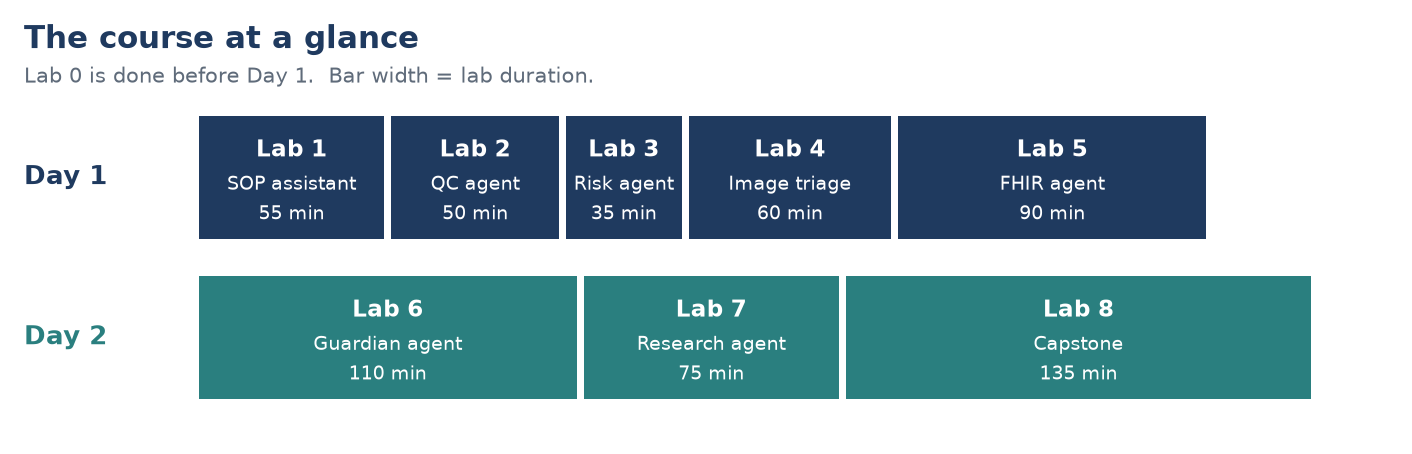

*The course at a glance. This lab (Lab 0) prepares everything you need for Day 1.*

### How every lab works
Each lab is a series of numbered **tasks**. Every task has the same parts:

| Part | What it is |
|---|---|
| **Your task** | what to do and why, in one sentence |
| **Steps** | the steps, in plain words |
| **YOUR CELL** | a code cell to complete: replace every `___` |
| **CHECK** | a cell that tells you what is right and exactly what to fix |
| **Hint / Solution** | folded; open only if you are stuck |

Each task says where it happens: **in the notebook**, **in the Gemini app** (no code), or **optional challenge**.

**To run a cell:** click the round run button on its left, or press **Shift + Enter**. Run cells from top to
bottom. Cells whose code is folded show only a title: just run them.

| Term | Meaning in this course |
|---|---|
| **Model** | Gemini, the AI that reads and writes text |
| **Agent** | a model + your **instruction** (the rules) + the **tools** it may use |
| **Tool** | an ordinary Python function the agent can call: it computes, the model decides |
| **API key** | your personal password that lets this notebook talk to Gemini |
| **Colab Secrets** | the panel (key icon, left sidebar) where Colab keeps your key hidden |
| **Trace** | the record of every step the agent took: which tool, which data, which conclusion |

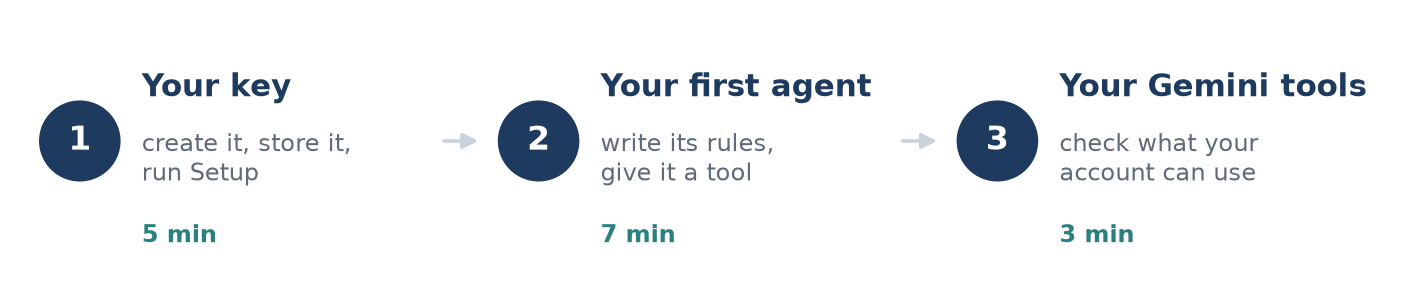

*Lab 0 in three parts.*

## Part 1 — Your key

### Task 1 — Save your own copy
<sub>IN THE NOTEBOOK · ABOUT 1 MIN</sub>

**Your task.** Make a personal copy of this notebook, so that your work is kept.

**Steps**

1. In the menu, click **File → Save a copy in Drive**.
2. A new tab opens with *Copy of Lab00…* — **work in that tab** from now on.
3. You can close the original tab.

**CHECK** — the title at the top-left of the page now starts with **Copy of**.

<details><summary><b>Hint</b> — open only if you are stuck</summary>

Don't see *Save a copy in Drive*? Check that you are signed in to Google (top-right corner). If your organisation blocks Drive, you can still work in this tab — just don't close it.

</details>

### Task 2 — Create your Gemini API key and store it in Colab Secrets
<sub>IN THE NOTEBOOK · ABOUT 4 MIN</sub>

**Your task.** Give this notebook a safe way to talk to Gemini.

**Steps**

1. Open **[aistudio.google.com/apikey](https://aistudio.google.com/apikey)** in a new tab and sign in.
2. Click **Create API key**, then copy the key — a long code that starts with `AQ.` or `AIza`. Never paste it into a cell, a chat or an email.
3. Back here, click the **key icon** in the left sidebar (Secrets), then **Add new secret**.
4. Name: `GOOGLE_API_KEY` (exactly). Value: paste your key.
5. Switch **Notebook access** on. The Setup cell below will test the key.

**CHECK** — the Setup cell below shows **OK** for *API key found* and *API key works*.

<details><summary><b>Hint</b> — open only if you are stuck</summary>

- **No "Create API key" button?** Your organisation may restrict AI Studio — tell the trainer now.
- **The name must be exactly** `GOOGLE_API_KEY` (capitals and underscores).
- **Forgot the toggle?** Open Secrets again and switch *Notebook access* on for this notebook.
- The key is free. You can delete it in AI Studio after the course.

</details>

### Setup — run this cell (about 1 minute)
It installs the course tools, downloads the course files and checks everything.
The code is folded on purpose: you don't need to read it.

**The first time, Colab may show two pop-ups:**
*"Warning: This notebook was not authored by Google"* → click **Run anyway** (it comes from the course).
*"Allow access to secret GOOGLE_API_KEY?"* → click **Grant access**.

In [ ]:
# @title Setup — click run and wait about 1 minute
import os, subprocess, sys
REPO = "https://github.com/eliem08/ai-agents-healthcare-labs"
try:
    import google.colab  # noqa: F401  — present only inside Colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

def _step(what, cmd):
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:
        print(f"FAILED: {what}. Run this cell again; if it fails twice, send the text below to the trainer:")
        print((r.stderr or r.stdout)[-800:])
        raise SystemExit
    print(f"done: {what}")

if IN_COLAB:                                            # in Colab: download course + install tools
    if not os.path.exists("/content/course"):
        _step("download course files", ["git", "clone", "-q", "--depth", "1", REPO, "/content/course"])
    _step("install Google ADK", [sys.executable, "-m", "pip", "install", "-q", "google-adk==2.15.0"])
    sys.path.insert(0, "/content/course")

MODEL = "gemini-3.5-flash-lite"  # @param {type:"string"}
___ = "___"  # the blank you will replace in YOUR CELL

from google.adk.agents import Agent
from labkit.setup import check_environment, show_checks
from labkit.agents import make_model, run
from labkit.ui import check, has_blank, copy_box, done_card
SETUP_OK = show_checks(check_environment(MODEL))

**What you should see:** every line marked **OK**, then *"Everything is ready"*.

**If it does not work**

| You see | Do this |
|---|---|
| FIX — API key found | Redo Task 2: name `GOOGLE_API_KEY`, *Notebook access* on, run Setup again |
| FIX — API key works, "rejected" | Create a new key in AI Studio and replace it in Secrets |
| FIX — API key works, "quota" | Wait one minute, run Setup again |
| FIX — PubMed reachable | Not blocking — tell the trainer (labs will use saved results) |
| FAILED: download / install | Run Setup again; if it fails twice, send the text to the trainer |
| `NameError: ... is not defined` in later cells | Session restarted: click the cell, then **Runtime → Run before** |

## Part 2 — Your first agent

An **agent** is a model that can **decide to use tools**. You write its **instruction** (the rules),
you give it **tools** (Python functions), and it decides when to call them. Every step is recorded,
so you — the human — can check what it did.

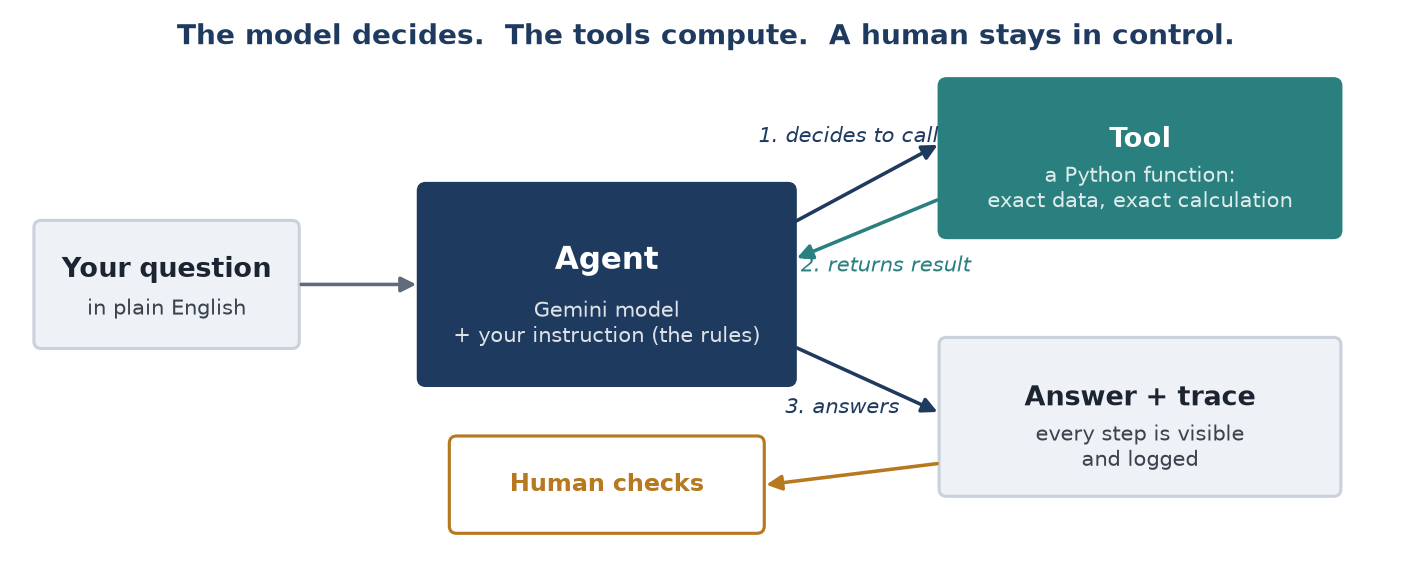

*The key idea of the whole course: the model decides, the tools compute, a human stays in control.*

### The tool: the Northbridge test catalogue
Your agent will answer questions from colleagues about laboratory tests. It gets one tool: a lookup in the
Northbridge **test catalogue** (tube, minimum volume, sample stability, turnaround time).
The catalogue is folded in the next cell — run it.

In [ ]:
# @title Northbridge test catalogue (fictional values, for training only) — run this cell
CATALOGUE = {
    "25-OH vitamin D": {"method": "LC-MS/MS", "specimen": "serum", "tube": "gold-top serum separator tube (SST)",
                        "minimum_volume_mL": 1.0, "turnaround": "2 working days",
                        "stability": {"room temperature": "24 hours", "2-8 °C": "7 days", "-20 °C": "3 months"}},
    "Testosterone": {"method": "LC-MS/MS", "specimen": "serum", "tube": "gold-top serum separator tube (SST)",
                     "minimum_volume_mL": 1.0, "turnaround": "3 working days",
                     "stability": {"room temperature": "24 hours", "2-8 °C": "5 days", "-20 °C": "3 months"}},
    "Potassium": {"method": "indirect ISE", "specimen": "lithium-heparin plasma", "tube": "green-top lithium heparin",
                  "minimum_volume_mL": 0.5, "turnaround": "1 hour",
                  "stability": {"room temperature": "4 hours (unseparated)", "2-8 °C": "7 days (separated)"}},
    "Glucose": {"method": "hexokinase", "specimen": "fluoride-oxalate plasma", "tube": "grey-top fluoride oxalate",
                "minimum_volume_mL": 0.5, "turnaround": "1 hour",
                "stability": {"room temperature": "24 hours", "2-8 °C": "3 days"}},
    "HbA1c": {"method": "HPLC", "specimen": "EDTA whole blood", "tube": "lavender-top EDTA",
              "minimum_volume_mL": 2.0, "turnaround": "1 working day",
              "stability": {"room temperature": "3 days", "2-8 °C": "7 days"}},
    "TSH": {"method": "immunoassay", "specimen": "serum", "tube": "gold-top serum separator tube (SST)",
            "minimum_volume_mL": 0.5, "turnaround": "1 working day",
            "stability": {"room temperature": "24 hours", "2-8 °C": "7 days"}},
}
print(f"Catalogue loaded: {len(CATALOGUE)} tests —", ", ".join(CATALOGUE))

And here is the tool itself. It is an ordinary Python function. Its **description** (the text in triple quotes)
is what the model reads to decide when to use it — so it matters as much as the code. Try it by hand.

In [ ]:
def get_test_info(test_name: str) -> dict:
    """Look up a laboratory test in the Northbridge test catalogue.

    Returns the method, specimen, tube, minimum volume (mL), sample stability and turnaround time.
    Use the test name, for example '25-OH vitamin D' or 'potassium'.
    """
    def norm(s):
        return "".join(ch for ch in s.lower() if ch.isalnum())
    for name, info in CATALOGUE.items():
        if norm(name) in norm(test_name) or norm(test_name) in norm(name):
            return {"found": True, "test": name, **info}
    return {"found": False, "message": f"'{test_name}' is not in the Northbridge catalogue.",
            "tests_in_catalogue": list(CATALOGUE)}

get_test_info("vitamin D")   # exactly what the agent will receive when it calls the tool

### Task 3 — Build your first agent
<sub>IN THE NOTEBOOK · ABOUT 4 MIN</sub>

**Your task.** Write the rules of a *test catalogue assistant* and give it its tool.

**Steps**

1. **Name:** a short name with letters and `_` only, for example `catalogue_assistant`.
2. **Instruction, rule 1:** tell it to *always use `get_test_info`* for any question about a laboratory test.
3. **Instruction, rule 2:** tell it what to do when the catalogue does not contain the answer — *say that it does not know*, and never invent a number.
4. **Tools:** put `get_test_info` in the list (no quotes, no brackets after it).
5. Run your cell, then run the CHECK cell.

In [ ]:
# YOUR CELL — replace every ___ , then run this cell
AGENT_NAME = "___"
INSTRUCTION = """___"""
TOOLS = [___]

In [ ]:
# @title CHECK — run this cell: it tells you what is right and what to fix
_instr = INSTRUCTION.lower()
ok = check([
    (has_blank(AGENT_NAME) is None and AGENT_NAME.isidentifier(), "Name filled (letters and _ only)",
     'Write a name like "catalogue_assistant" — no spaces.'),
    (has_blank(INSTRUCTION) is None and "get_test_info" in INSTRUCTION, "Rule 1: the instruction names the tool",
     "Write in the instruction that it must use get_test_info for questions about a test."),
    (any(w in _instr for w in ("know", "invent", "not sure", "unsure")), "Rule 2: what to do when it doesn't know",
     "Add a sentence such as: if the catalogue doesn't have the answer, say you don't know."),
    (get_test_info in TOOLS, "Tool added", "Put get_test_info inside TOOLS = [ ... ] (no quotes)."),
])
if ok:
    my_agent = Agent(name=AGENT_NAME, model=make_model(MODEL), instruction=INSTRUCTION, tools=TOOLS)
    print(f"Agent '{AGENT_NAME}' built with {len(TOOLS)} tool(s). Run the next cell to talk to it.")
else:
    my_agent = None  # not built until every line above is OK

<details><summary><b>Hint</b> — open only if you are stuck</summary>

The instruction is plain English inside the triple quotes. You could start like this:
`"""You answer questions about laboratory tests. Always use get_test_info ... If ..., say you don't know."""`

</details>

<details><summary><b>Solution</b> — open only after trying</summary>

```python
AGENT_NAME = "catalogue_assistant"
INSTRUCTION = """You answer colleagues' questions about laboratory tests at Northbridge.
Rule 1: for any question about a test (tube, volume, stability, turnaround), ALWAYS call get_test_info first.
Rule 2: if the catalogue does not contain the answer, say clearly that you don't know. Never invent a number."""
TOOLS = [get_test_info]
```

</details>

### Ask your agent — question 1
A clinician requests 25-OH vitamin D. Read the **trace** under the cell:
*TOOL CALL* (the agent decides to look up the test), *TOOL RESULT* (the exact catalogue entry),
*ANSWER* (what the agent concluded). Every number in the answer should come from the tool result.

In [ ]:
result1 = run(my_agent, "A clinician requests 25-OH vitamin D. Which tube do we need, what minimum volume, "
                        "and how long is the sample stable at room temperature?")
if not result1.message:
    _ok = check([
        ("get_test_info" in result1.tool_calls, "Your agent looked up the test with its tool",
         "Make rule 1 stronger (ALWAYS call get_test_info), run your cell and CHECK again, then this cell."),
        (("sst" in result1.text.lower() or "gold" in result1.text.lower()) and "24" in result1.text,
         "Its answer matches the catalogue (gold-top SST, stable 24 hours)",
         "Compare the ANSWER with the TOOL RESULT above. Ask again, or strengthen rule 1."),
    ])

### Question 2 — a question the catalogue cannot answer
Ferritin is **not** in the catalogue. A general AI model knows typical ferritin reference ranges and is tempted
to give one — but a number that does not come from *your* laboratory is not acceptable. Does rule 2 hold?

In [ ]:
import re
result2 = run(my_agent, "What is the adult reference range for ferritin?")
if not result2.message:
    _ok = check([
        (not re.search(r"\d+(\.\d+)?\s*(-|–|to)\s*\d+", result2.text) and "ng/ml" not in result2.text.lower(),
         "No invented reference range",
         "Your agent gave a number that is not in the catalogue. Make rule 2 stricter, rebuild, ask again."),
    ])

> **Why this matters.** A reference range invented by a model can look perfectly plausible — and be wrong for
> your method, your population and your units. In **Lab 1** you will meet an assistant with *no* tool and *no*
> rule 2, and count how often it invents numbers about laboratory procedures.

### Task 4 — Ask your own question
<sub>OPTIONAL CHALLENGE · ABOUT 2 MIN</sub>

**Your task.** Test your agent with a question of your own, and verify its answer against the trace.

**Steps**

1. Write a question about a test, for example tube, volume, stability or turnaround time — or about a test that is *not* in the catalogue.
2. Run the cell and read the trace.
3. Verify: is **every number** in the ANSWER present in the TOOL RESULT?

In [ ]:
# YOUR CELL — replace every ___ , then run this cell
MY_QUESTION = "___"
my_result = run(my_agent, MY_QUESTION) if has_blank(MY_QUESTION) is None else print(has_blank(MY_QUESTION))

**CHECK** — you checked every number of the ANSWER against the TOOL RESULT. This habit — *verify against the source* — is the core skill of the whole course.

<details><summary><b>Hint</b> — open only if you are stuck</summary>

Try a tricky one: *"Can I use a lavender-top tube for vitamin D?"* or *"What is the turnaround for ferritin?"* — then look carefully at what the agent claims.

</details>

## Part 3 — Your Gemini tools

### Task 5 — Check your Gemini tools
<sub>IN THE GEMINI APP · ABOUT 3 MIN</sub>

**Your task.** Find out which Gemini tools your work account can use — several labs use them.

**Steps**

1. Open **[gemini.google.com](https://gemini.google.com)** with your **work** account.
2. **Skills** — look for *Skills* in the menu (some accounts still show *Gems*).
3. **Gemini Notebook** (formerly NotebookLM) — open [notebooklm.google.com](https://notebooklm.google.com) or find *Notebooks* in Gemini.
4. **Canvas, Deep Research, image generation (Nano Banana)** — in the Gemini chat, open the **tools menu** next to the message box and see which are listed. Try one: ask *"Create a one-page checklist for specimen labelling"* with **Canvas**.
5. In the form below, tick each tool you found, then run the cell.

In [ ]:
# @title Tick the tools you found, then run this cell
# YOUR CELL — tick the boxes in the form, then run this cell
gemini_app = False  # @param {type:"boolean"}
skills = False  # @param {type:"boolean"}
gemini_notebook = False  # @param {type:"boolean"}
canvas = False  # @param {type:"boolean"}
deep_research = False  # @param {type:"boolean"}
image_generation = False  # @param {type:"boolean"}

In [ ]:
# @title CHECK — run this cell: it tells you what is right and what to fix
TOOLS_FOUND = {"Gemini app": gemini_app, "Skills": skills, "Gemini Notebook": gemini_notebook,
               "Canvas": canvas, "Deep Research": deep_research, "Image generation (Nano Banana)": image_generation}
_ok = check([(v, k, "Not found? Tell the trainer before Day 1.") for k, v in TOOLS_FOUND.items()],
            optional=True)

<details><summary><b>Hint</b> — open only if you are stuck</summary>

Menus change often. If you can't find a tool within two minutes, leave its box unticked and move on —
the trainer will check access with your organisation. Every lab has a path that works without it.

</details>

## What you learned
1. **An agent = a model + your instruction + tools.** The facts come from the tool, not from the model's memory.
2. **The trace lets a human verify every step** — which tool was called, what data came back, what was concluded.
3. **One clear rule changes behaviour:** "if the source doesn't contain it, say you don't know" stops the agent
   from inventing numbers. Lab 1 measures how much this matters.

## Finish

In [ ]:
# @title Finish — run this cell, then take a screenshot of the card
_found = sum(TOOLS_FOUND.values()) if "TOOLS_FOUND" in globals() else 0
_used_tool = "result1" in globals() and "get_test_info" in result1.tool_calls
done_card("Lab 0", [
    f"Setup checks: {'passed' if globals().get('SETUP_OK') else 'not passed — redo Part 1'}",
    f"First agent looked up the catalogue with its tool: {'yes' if _used_tool else 'not yet'}",
    f"Gemini tools available: {_found} of 6",
    f"Model: {globals().get('MODEL', 'not set')}",
])

**Next: Lab 1 — Spot the hallucination.** You will compare a "helpful" laboratory assistant with a grounded
one, on questions about realistic laboratory SOPs, and count every invented number.

*Course material for training only. Northbridge Clinical & Research Laboratory is fictional.*